# QQQ Volatility Forecasting: Regression

**เล่มนี้ตอบคำถามเดียว:** โมเดล regression 4 ตัวที่เราเขียนเอง ทำนายความผันผวนของ QQQ ใน 5 วันทำการข้างหน้าได้ดีแค่ไหน

**ขอบเขต**

- เล่มนี้ **อ่านผลที่เทรนไว้แล้ว** จาก `outputs/modeling/` ไม่เทรนโมเดลใหม่ จึงรันจบในไม่ถึงนาที
- ไม่มี cell ใดเปิด Test set ตัวเลขทุกตัวในเล่มนี้วัดบน Validation
- โมเดลทั้ง 4 ตัว (`simple_linear`, `multiple_linear`, `polynomial`, `elastic_net`) เขียนด้วย NumPy ล้วน ส่วน scikit-learn ใช้เพียงเพื่อยืนยันว่าเราเขียนถูก (หัวข้อ 8)

**ต้องรันอะไรก่อน:** `python -m src.ml.run report`, `compare` และ `analyze` (ดู `docs/guides/RUNBOOK.md`) ถ้าไฟล์ขาด notebook จะหยุดและบอกชื่อไฟล์ที่ขาด

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
project_root = current.parent if current.name == "notebooks" else current
if not (project_root / "config.py").is_file() or not (project_root / "src").is_dir():
    raise FileNotFoundError(f"Could not resolve project root from {current}; expected config.py and src/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.ml.core.artifacts import load_model, read_run, read_runs
from src.ml.core.compare import assert_parity
from src.ml.core.contracts import FEATURE_COLUMNS, VARIANTS
from src.ml.core.data import load
from src.ml.core.trainer import OUTPUT_ROOT, evaluate

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
REPORT_ROOT = OUTPUT_ROOT / "report"
FIGURE_ROOT = project_root / "outputs" / "figures" / "modeling"
TASK = 'regression'


def require_files(paths):
    missing = [str(path) for path in paths if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing generated artifacts (run `python -m src.ml.run report/compare/analyze` first):\n"
            + "\n".join(missing)
        )


def table(path):
    require_files([path])
    return pd.read_csv(path)


# src.ml.core.figures selects the file-only Agg backend; switch back so charts drawn in
# this notebook are shown inline.
get_ipython().run_line_magic("matplotlib", "inline")


def show_markdown(path):
    require_files([path])
    display(Markdown(Path(path).read_text(encoding="utf-8")))


def show_image(path, width=900):
    require_files([path])
    display(Image(filename=str(path), width=width))

## 1. โจทย์ regression

**สิ่งที่ต้องทำนาย** คือ `target_volatility_5d` = ส่วนเบี่ยงเบนมาตรฐานของผลตอบแทนรายวันใน 5 วันทำการถัดไป (วัน t+1 ถึง t+5) คูณ √252 เพื่อแปลงเป็นหน่วยต่อปี เช่น 0.20 แปลว่าผันผวนราว 20% ต่อปี

**สิ่งที่โมเดลเห็น** คือ feature 8 ตัวที่คำนวณจากข้อมูลถึงวัน t เท่านั้น โมเดลจึงไม่มีทางเห็นอนาคต

ความผันผวนติดลบไม่ได้ แต่สมการเส้นตรงให้ค่าติดลบได้ เราจึง **clip ที่ 0** ก่อนคิดคะแนน และเก็บทั้งคะแนนก่อน clip (`raw_metrics`) และหลัง clip (`clipped_metrics`)

ตารางถัดไปสรุปขนาดและการกระจายของ target ในแต่ละชุดข้อมูล `with_spike` คือ Train เต็ม ส่วน `non_spike` คือ Train ที่ตัดช่วงรอบวันราคากระชากออก ทั้งสองแบบใช้ Validation ชุดเดียวกัน

In [2]:
data = {variant: load(variant) for variant in VARIANTS}
summary = []
for variant, dataset in data.items():
    for split in (dataset.train, dataset.validation):
        y = split.y_regression
        summary.append({"variant": variant, "split": split.name, "rows": len(y),
                        "from": str(split.dates[0])[:10], "to": str(split.dates[-1])[:10],
                        "target mean": y.mean(), "target std": y.std(ddof=1), "target max": y.max()})
display(pd.DataFrame(summary).round(4))

,variant,split,rows,from,to,target mean,target std,target max
0,with_spike,train,1733,2016-09-29,2023-08-18,0.1938,0.1435,1.5017
1,with_spike,validation,371,2023-08-28,2025-02-19,0.1605,0.0675,0.4130
2,non_spike,train,1520,2016-09-29,2023-08-18,0.1664,0.0987,0.5493
3,non_spike,validation,371,2023-08-28,2025-02-19,0.1605,0.0675,0.4130


**อ่านตาราง:** Validation สงบกว่า Train มาก (ดูคอลัมน์ `target std` และ `target max`) เรื่องนี้สำคัญกับ R² ในหัวข้อถัดไป เพราะเมื่อค่าจริงแกว่งน้อย การ "ทายค่าเฉลี่ย" ก็ผิดไม่มาก โมเดลจึงเอาชนะได้ยาก

## 2. อ่าน metric อย่างไร

| Metric | ความหมายแบบสั้น | ยิ่งดีเมื่อ |
| --- | --- | --- |
| **RMSE** | ขนาดความผิดพลาดเฉลี่ย โดยลงโทษการผิดมาก ๆ หนักเป็นพิเศษ (ยกกำลังสองก่อนเฉลี่ย) | ต่ำ |
| **MAE** | ขนาดความผิดพลาดเฉลี่ยแบบตรงไปตรงมา | ต่ำ |
| **R²** | โมเดลดีกว่า "ทายค่าเฉลี่ยของชุดที่วัด" เท่าไร 1 = สมบูรณ์แบบ, 0 = เท่ากับทายค่าเฉลี่ย | สูง |

R² **ติดลบได้** และแปลว่าโมเดลแย่กว่าการทายค่าเฉลี่ยของ Validation เสียอีก ซึ่งเกิดขึ้นจริงในโปรเจกต์นี้ เพราะโมเดลเรียนจาก Train ที่ผันผวนกว่า Validation มาก

ตารางถัดไปคือการตั้งค่าที่ชนะของแต่ละโมเดล เราลองหลายค่า (grid search) แล้วเลือกชุดที่ RMSE หลัง clip บน Validation ต่ำที่สุด

In [3]:
runs = {variant: read_runs(OUTPUT_ROOT, variant, task=TASK) for variant in VARIANTS}
chosen = []
for variant, items in runs.items():
    for run in items:
        search = json.loads((run.directory / "search_results.json").read_text(encoding="utf-8"))
        chosen.append({"variant": variant, "model": run.name, "candidates tried": len(search),
                       "selected": run.config["selected_candidate"], "params": json.dumps(run.config["params"]),
                       "preprocess": run.config["preprocess"],
                       "validation rmse": run.metrics["clipped_metrics"]["rmse"]["value"]})
display(pd.DataFrame(chosen).round(5))

,variant,model,candidates tried,selected,params,preprocess,validation rmse
0,with_spike,elastic_net,12,elastic_net-09,"{""alpha"": 0.1, ""l1_ratio"": 0.25, ""max_iter"": 5000, ""tol"": 1e-06}",standardize,0.06681
1,with_spike,multiple_linear,1,multiple_linear-00,"{""fit_intercept"": true}",standardize,0.06886
2,with_spike,polynomial,16,polynomial-11,"{""degree"": 3, ""feature"": ""historical_volatility_20d"", ""standardize_before_po...",standardize,0.06906
3,with_spike,simple_linear,8,simple_linear-03,"{""feature"": ""historical_volatility_20d""}",none,0.06904
4,non_spike,elastic_net,12,elastic_net-09,"{""alpha"": 0.1, ""l1_ratio"": 0.25, ""max_iter"": 5000, ""tol"": 1e-06}",standardize,0.06426
5,non_spike,multiple_linear,1,multiple_linear-00,"{""fit_intercept"": true}",standardize,0.06682
6,non_spike,polynomial,16,polynomial-01,"{""degree"": 2, ""feature"": ""return_5d"", ""standardize_before_powers"": true}",standardize,0.06606
7,non_spike,simple_linear,8,simple_linear-00,"{""feature"": ""return_1d""}",none,0.06648


## 3. Baseline ที่ต้องชนะให้ได้

ตัวเลข RMSE เดี่ยว ๆ บอกไม่ได้ว่าดีหรือแย่ ต้องมีคู่เทียบที่ **ไม่ต้องใช้ ML เลย** เราใช้สองตัว

- `baseline_train_mean`: ทายค่าเฉลี่ยของ target ใน Train ทุกวัน
- `baseline_persistence`: ทายว่า 5 วันข้างหน้าจะผันผวนเท่ากับ 5 วันที่เพิ่งผ่านมา (`historical_volatility_5d` ของวัน t)

ทั้งสองไม่มี leakage เพราะใช้เฉพาะข้อมูลที่รู้ ณ สิ้นวัน t

**วิธีอ่านตาราง**

- `rmse_ci` เขียนเป็น `ค่า [ต่ำ, สูง]` ช่วงในวงเล็บคือช่วงความเชื่อมั่น 95% หมายความว่าถ้าได้ Validation ชุดอื่นที่คล้ายกัน ค่าน่าจะตกอยู่ในช่วงนี้ เราคำนวณด้วย block bootstrap (สุ่มซ้ำเป็นก้อน 20 วันติดกัน) เพราะข้อมูลวันติดกันไม่อิสระต่อกัน
- `tied_with_leader = yes` แปลว่าแยกจากอันดับ 1 ไม่ได้ทางสถิติ ห้ามพูดว่าตัวไหนดีกว่ากันภายในกลุ่มนี้
- `beats_best_baseline` บอกว่าคะแนนดีกว่า baseline ตัวที่ดีที่สุดหรือไม่
- ตัวเลขทั้งหมดเป็น **selection score**: เราเลือกการตั้งค่าบน Validation ชุดนี้เอง ตัวเลขจึงดูดีกว่าความจริงเล็กน้อย

In [4]:
for variant in VARIANTS:
    show_markdown(REPORT_ROOT / variant / "leaderboard_regression.md")

### Validation leaderboard — regression — with_spike

| model | kind | rmse_ci | mae | r2_ci | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- |
| elastic_net | model | 0.0668 [0.0610, 0.0739] | 0.0539 | 0.0169 [-0.2649, 0.2159] | yes | yes |
| multiple_linear | model | 0.0689 [0.0617, 0.0779] | 0.0542 | -0.0446 [-0.3994, 0.2085] | yes | yes |
| simple_linear | model | 0.0690 [0.0609, 0.0789] | 0.0557 | -0.0498 [-0.2829, 0.0997] | yes | yes |
| polynomial | model | 0.0691 [0.0606, 0.0797] | 0.0552 | -0.0507 [-0.2579, 0.0879] | yes | yes |
| baseline_train_mean | baseline | 0.0751 [0.0673, 0.0837] | 0.0623 | -0.2430 [-0.6975, -0.0225] | no | n/a |
| baseline_persistence | baseline | 0.0826 [0.0750, 0.0901] | 0.0673 | -0.5032 [-1.0576, -0.0677] | no | n/a |

> ตัวเลขบน Validation เป็น selection score: hyperparameter ของทุกโมเดลถูกเลือกบนแถวชุดนี้ จึงมองโลกในแง่ดีเกินจริง และโมเดลที่ `tied_with_leader = yes` แยกจากอันดับ 1 ไม่ได้ที่ระดับ 95% (moving-block bootstrap, block 20 วัน) ห้ามอ้างอันดับภายในกลุ่มนั้น
> 4 จาก 4 โมเดลอยู่ในกลุ่มที่แยกจากอันดับ 1 ไม่ได้


### Validation leaderboard — regression — non_spike

| model | kind | rmse_ci | mae | r2_ci | tied_with_leader | beats_best_baseline |
| --- | --- | --- | --- | --- | --- | --- |
| elastic_net | model | 0.0643 [0.0572, 0.0741] | 0.0510 | 0.0906 [-0.0841, 0.2010] | yes | yes |
| polynomial | model | 0.0661 [0.0596, 0.0755] | 0.0509 | 0.0389 [-0.1903, 0.1745] | yes | yes |
| simple_linear | model | 0.0665 [0.0582, 0.0783] | 0.0527 | 0.0265 [-0.1099, 0.0616] | yes | yes |
| multiple_linear | model | 0.0668 [0.0597, 0.0761] | 0.0530 | 0.0165 [-0.2942, 0.2361] | yes | yes |
| baseline_train_mean | baseline | 0.0676 [0.0585, 0.0805] | 0.0535 | -0.0076 [-0.1436, -0.0000] | yes | n/a |
| baseline_persistence | baseline | 0.0826 [0.0750, 0.0901] | 0.0673 | -0.5032 [-1.0576, -0.0677] | no | n/a |

> ตัวเลขบน Validation เป็น selection score: hyperparameter ของทุกโมเดลถูกเลือกบนแถวชุดนี้ จึงมองโลกในแง่ดีเกินจริง และโมเดลที่ `tied_with_leader = yes` แยกจากอันดับ 1 ไม่ได้ที่ระดับ 95% (moving-block bootstrap, block 20 วัน) ห้ามอ้างอันดับภายในกลุ่มนั้น
> 4 จาก 4 โมเดลอยู่ในกลุ่มที่แยกจากอันดับ 1 ไม่ได้


**สิ่งที่ตารางบอก**

- โมเดลทั้ง 4 ตัวได้ RMSE ต่ำกว่า baseline ทั้งสองตัว
- แต่ทั้ง 4 ตัวอยู่ในกลุ่ม `tied_with_leader` จึงบอกไม่ได้ว่าตัวไหนดีที่สุด
- R² อยู่ใกล้ 0 หรือติดลบ โมเดลจึงอธิบายความแปรปรวนของ Validation ได้น้อยมาก ถึงจะชนะ baseline ก็ตาม

## 4. ทำนายเทียบค่าจริง

แต่ละจุดคือหนึ่งวันใน Validation แกนนอนคือค่าจริง แกนตั้งคือค่าที่โมเดลทำนาย

- จุดบนเส้นประทแยง = ทำนายถูกพอดี
- จุดเรียงตัวเป็นแถบแนวนอน = โมเดลทำนายค่าใกล้เดิมทุกวัน ไม่ขยับตามค่าจริง

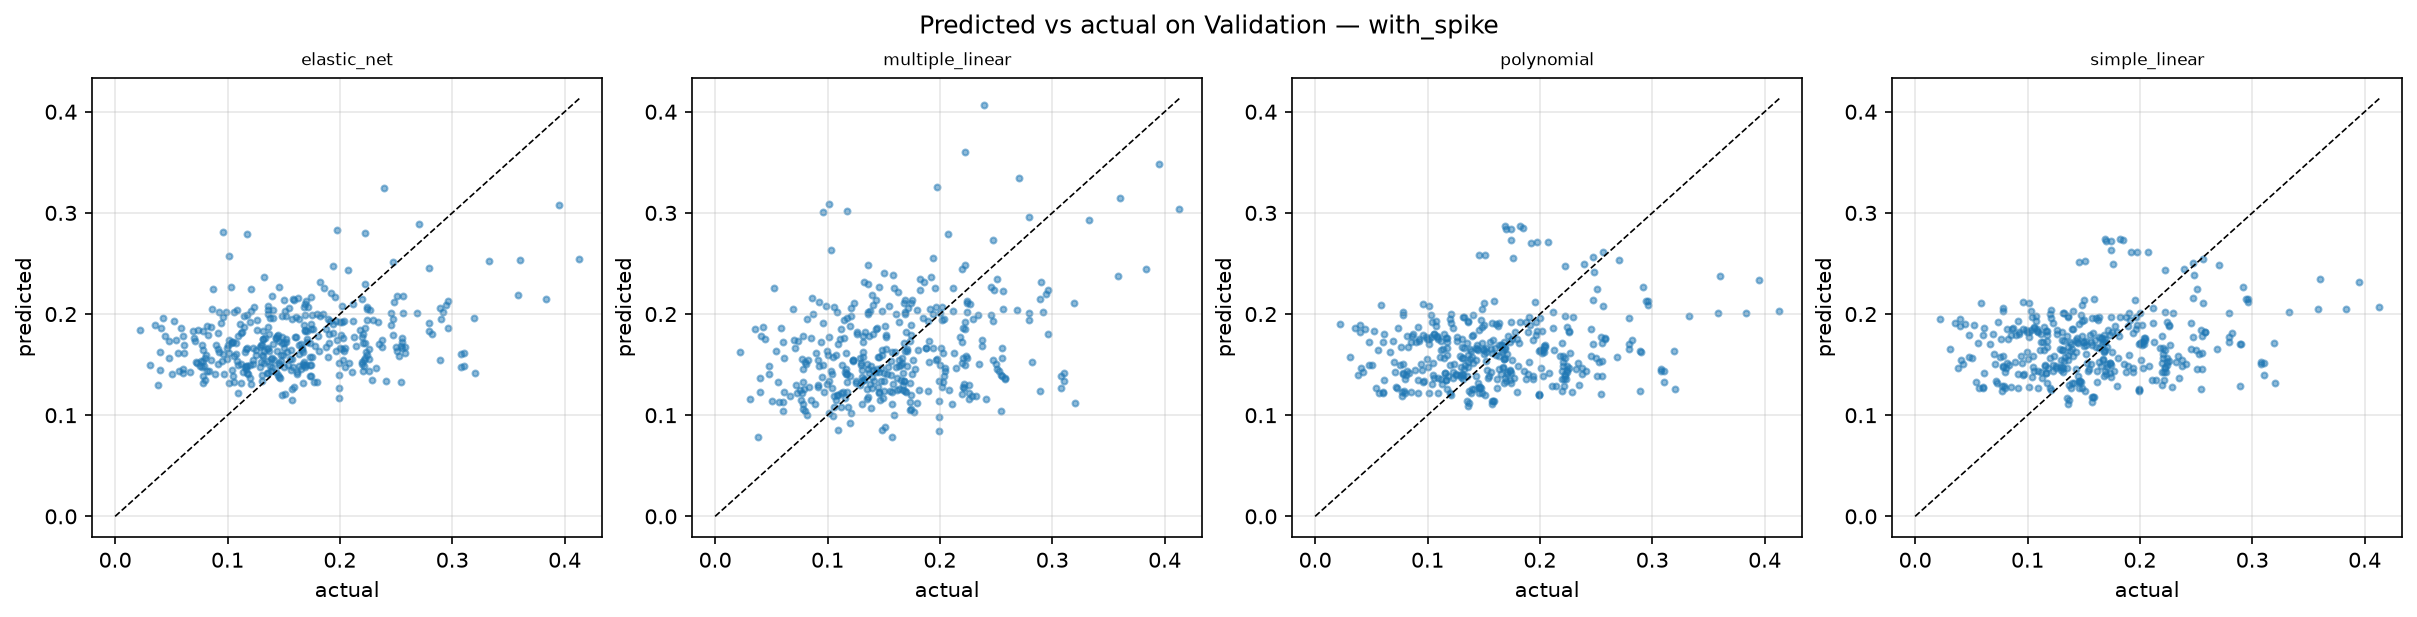

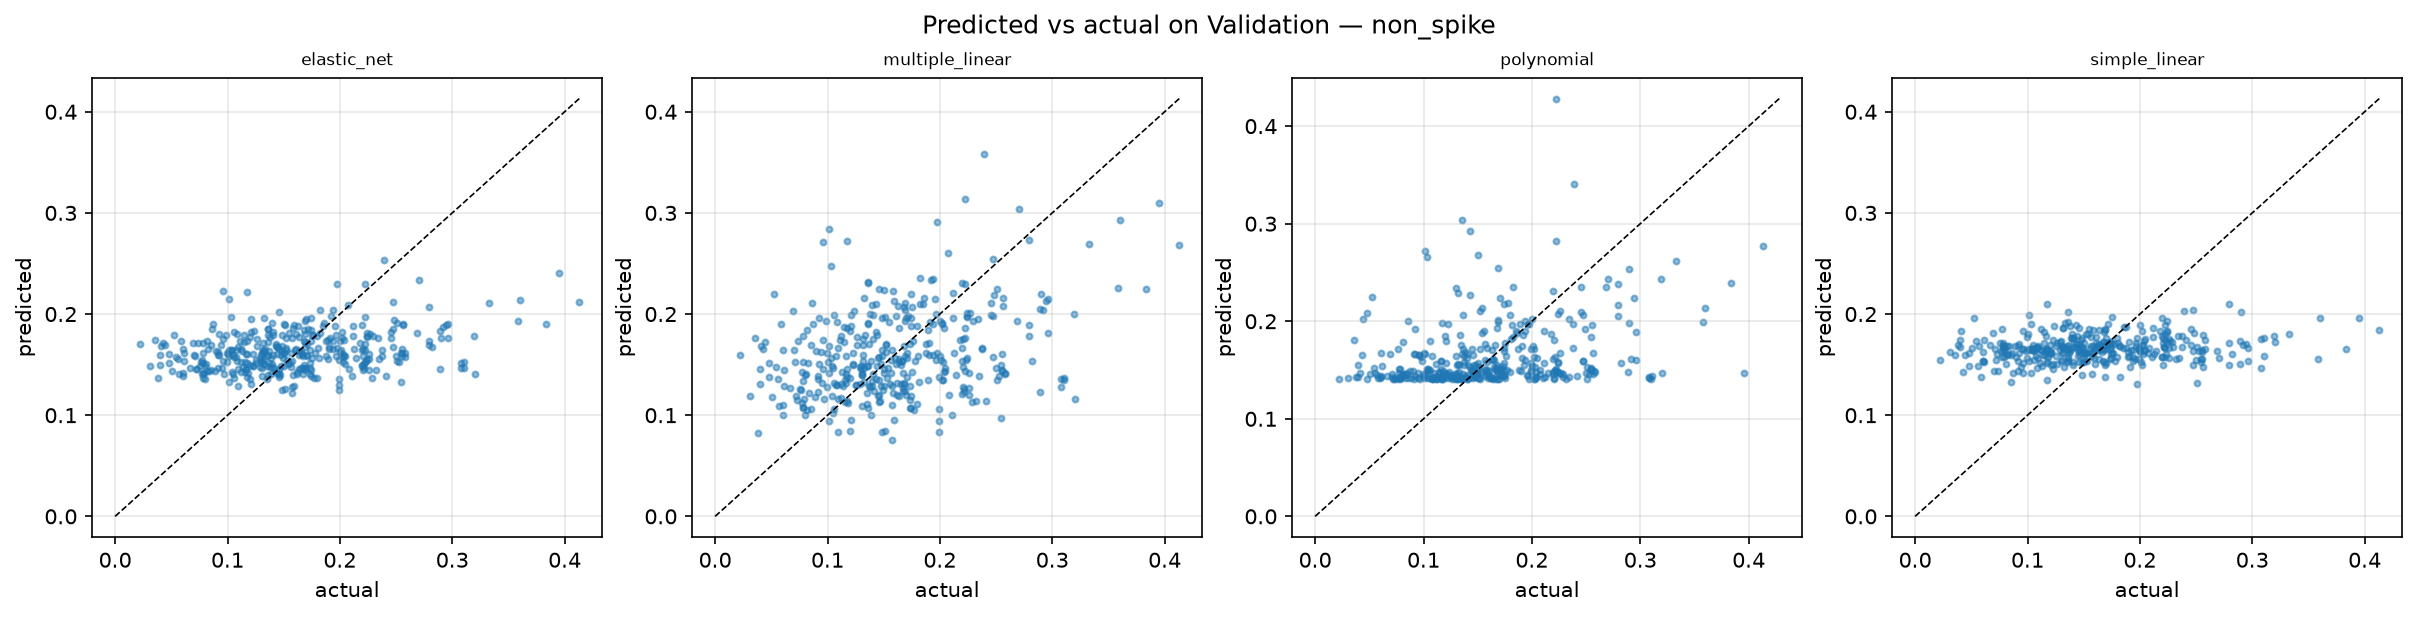

In [5]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "regression_predicted_vs_actual.png", width=1000)

รูปถัดไปคือ **residual** (ค่าจริง ลบ ค่าทำนาย) เรียงตามเวลา ถ้าโมเดลดี residual ควรแกว่งรอบศูนย์แบบไม่มีรูปแบบ ช่วงที่ residual พุ่งขึ้นพร้อมกันทุกโมเดลคือช่วงที่ตลาดเปลี่ยนสภาพเร็วกว่าที่ feature ย้อนหลังจะตามทัน

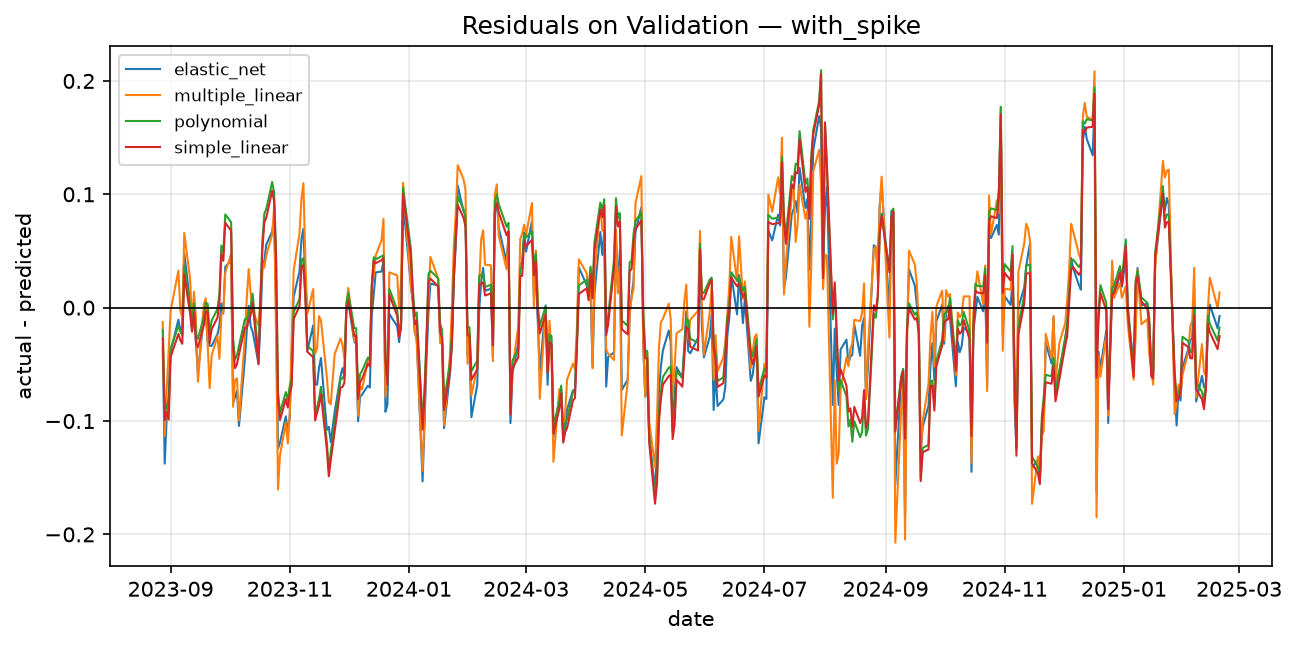

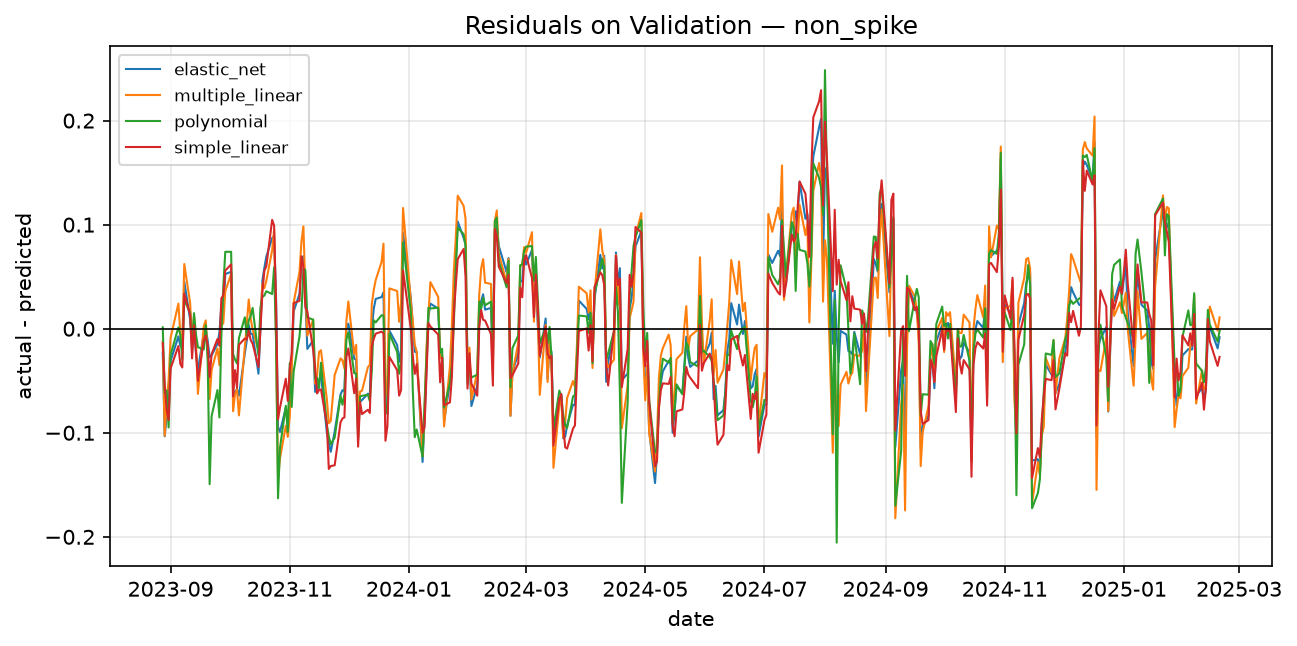

In [6]:
for variant in VARIANTS:
    show_image(FIGURE_ROOT / variant / "regression_residuals.png", width=1000)

## 5. Elastic Net: โมเดลนอกห้องเรียน

Elastic Net คือ linear regression ที่เพิ่ม "ค่าปรับ" เมื่อน้ำหนัก (coefficient) มีขนาดใหญ่ สิ่งที่มันพยายามทำให้ต่ำที่สุดคือ

$$\frac{1}{2n}\lVert y - Xw \rVert_2^2 + \alpha\left[\rho\lVert w\rVert_1 + \frac{1-\rho}{2}\lVert w\rVert_2^2\right]$$

- `alpha` (α) คือความแรงของค่าปรับ ยิ่งมากน้ำหนักยิ่งถูกบีบเข้าหาศูนย์
- `l1_ratio` (ρ) คือสัดส่วนระหว่างค่าปรับแบบ L1 (ทำให้น้ำหนักบางตัว **เป็นศูนย์พอดี** เท่ากับคัด feature ทิ้ง) กับแบบ L2 (ทำให้น้ำหนักเล็กลงแต่ไม่เป็นศูนย์)

**ทำไมเหมาะกับข้อมูลนี้:** feature บางคู่พูดเรื่องเดียวกัน เช่น `historical_volatility_5d` กับ `historical_volatility_20d` (สหสัมพันธ์บน Train ราว 0.80) linear ธรรมดาจะแบ่งน้ำหนักให้คู่นี้แบบไม่นิ่ง Elastic Net ถูกออกแบบมาแก้จุดนี้

เราเขียนด้วย coordinate descent: ปรับน้ำหนักทีละตัวโดยตรึงตัวอื่นไว้ และใช้ soft-threshold เพื่อดันน้ำหนักที่เล็กเกินไปให้เป็นศูนย์

ตารางถัดไปคือ RMSE ของทุกช่องใน grid ที่ลอง

In [7]:
for variant in VARIANTS:
    run = read_run(OUTPUT_ROOT, variant, "elastic_net")
    search = json.loads((run.directory / "search_results.json").read_text(encoding="utf-8"))
    grid = pd.DataFrame([{"alpha": item["params"]["alpha"], "l1_ratio": item["params"]["l1_ratio"],
                          "rmse": item["metrics"]["clipped_metrics"]["rmse"]["value"]} for item in search])
    print(f"{variant}: selected {run.config['selected_candidate']} -> alpha={run.config['params']['alpha']}, "
          f"l1_ratio={run.config['params']['l1_ratio']}")
    display(grid.pivot(index="alpha", columns="l1_ratio", values="rmse").round(5))

with_spike: selected elastic_net-09 -> alpha=0.1, l1_ratio=0.25


l1_ratio,0.25,0.50,0.75
alpha,,,
0.0001,0.06887,0.06887,0.06888
0.0010,0.06892,0.06899,0.06907
0.0100,0.06884,0.06829,0.06798
0.1000,0.06681,0.06812,0.07175


non_spike: selected elastic_net-09 -> alpha=0.1, l1_ratio=0.25


l1_ratio,0.25,0.50,0.75
alpha,,,
0.0001,0.06681,0.06681,0.06680
0.0010,0.06675,0.06668,0.06661
0.0100,0.06620,0.06584,0.06550
0.1000,0.06426,0.06696,0.06764


รูปถัดไปเทียบ coefficient ของ `multiple_linear` (ไม่มีค่าปรับ) กับ `elastic_net` ข้อมูลถูก standardize ก่อน coefficient จึงเทียบขนาดข้าม feature ได้ แท่งที่หายไปในฝั่ง Elastic Net คือ feature ที่ถูกดันเป็นศูนย์

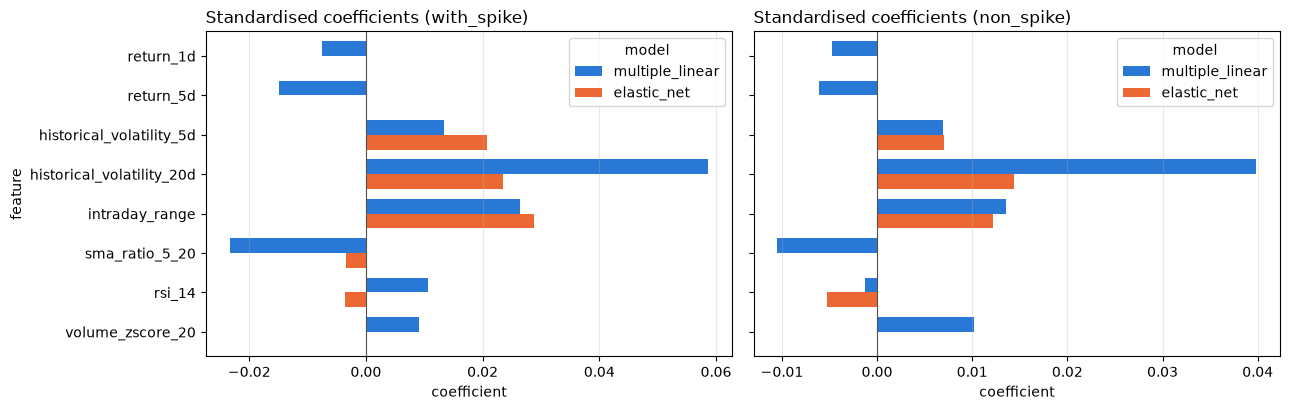

Elastic Net coefficients that are exactly zero: {'with_spike': 3, 'non_spike': 4} of 8


In [8]:
figure, panels = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for axes, variant in zip(panels, VARIANTS):
    coefficients = table(REPORT_ROOT / variant / "linear_coefficients.csv")
    wide = (coefficients[coefficients["model"].isin(["multiple_linear", "elastic_net"])]
            .pivot(index="feature", columns="model", values="coefficient")
            .reindex(list(FEATURE_COLUMNS))[["multiple_linear", "elastic_net"]])
    wide.plot.barh(ax=axes, color=["#2a78d6", "#eb6834"], width=0.75)
    axes.axvline(0, color="#52514e", linewidth=0.8)
    axes.set_title(f"Standardised coefficients ({variant})", loc="left")
    axes.set_xlabel("coefficient")
    axes.grid(axis="x", alpha=0.3)
    axes.invert_yaxis()
figure.tight_layout()
plt.show()
zeroed = {variant: int((table(REPORT_ROOT / variant / "linear_coefficients.csv")
                        .query("model == 'elastic_net'")["coefficient"] == 0).sum()) for variant in VARIANTS}
print("Elastic Net coefficients that are exactly zero:", zeroed, "of", len(FEATURE_COLUMNS))

## 6. Performance curve

Performance curve คือค่า loss ระหว่างเทรน ใช้ดูว่าโมเดลเรียนจนนิ่งแล้วหรือยัง

- `simple_linear`, `multiple_linear`, `polynomial` แก้สมการได้คำตอบในขั้นเดียว (closed form) จึงมีค่า loss จุดเดียว
- `elastic_net` วนปรับน้ำหนักหลายรอบ loss จึงลดลงจนนิ่ง

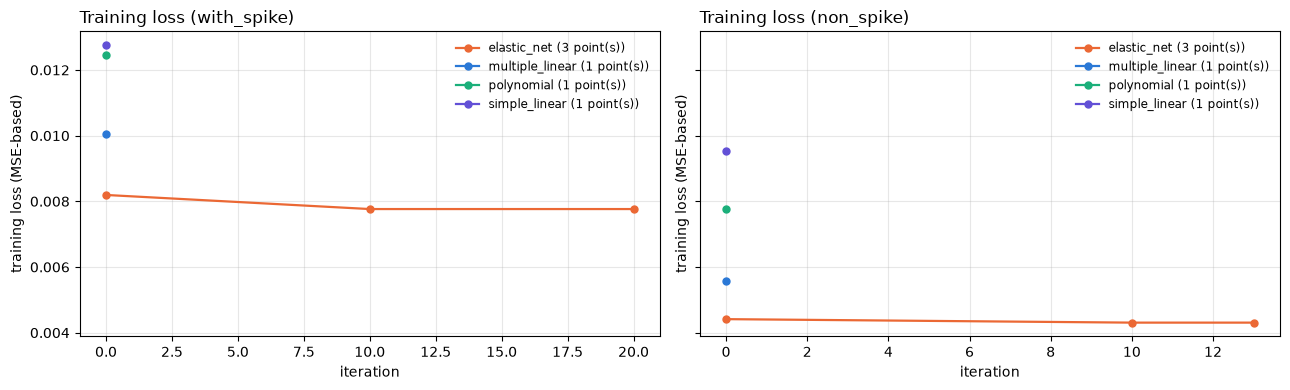

In [9]:
figure, panels = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
colors = dict(zip(["elastic_net", "multiple_linear", "polynomial", "simple_linear"],
                  ["#eb6834", "#2a78d6", "#1baf7a", "#6250d6"]))
for axes, variant in zip(panels, VARIANTS):
    for run in runs[variant]:
        history = run.history or {"iteration": [], "loss": []}
        axes.plot(history["iteration"], history["loss"], marker="o", markersize=5, linewidth=1.6,
                  color=colors[run.name], label=f"{run.name} ({len(history['loss'])} point(s))")
    axes.set_title(f"Training loss ({variant})", loc="left")
    axes.set_xlabel("iteration")
    axes.set_ylabel("training loss (MSE-based)")
    axes.grid(alpha=0.3)
    axes.legend(fontsize="small", frameon=False)
figure.tight_layout()
plt.show()

## 7. Save → load → ทำนายซ้ำ

โจทย์กำหนดว่าโมเดลต้องบันทึกลงไฟล์ โหลดกลับมา แล้วทำนายได้เหมือนเดิม เราพิสูจน์สองชั้น

1. `stored_passed`: ผลตรวจที่ trainer บันทึกไว้ตอนเทรน (`load_verification.json`)
2. `reproduced_here`: notebook นี้โหลด `model.npz` กับ `preprocessor.npz` ขึ้นมาใหม่ ทำนาย Validation อีกรอบ แล้วเทียบกับค่าที่บันทึกใน `validation_predictions.csv`

ทุกแถวต้องเป็น `True`

In [10]:
checks = []
for variant in VARIANTS:
    validation = data[variant].validation
    for run in runs[variant]:
        model, transform = load_model(run.directory)
        _, prediction, _ = evaluate(model, transform(validation.X), validation.y_regression,
                                    validation.y_classification, run.task)
        stored = json.loads((run.directory / "load_verification.json").read_text(encoding="utf-8"))
        checks.append({"variant": variant, "model": run.name, "stored_passed": stored["passed"],
                       "reproduced_here": bool(np.allclose(prediction, run.prediction, rtol=1e-10, atol=1e-12)),
                       "max_abs_diff": float(np.abs(prediction - run.prediction).max())})
checks = pd.DataFrame(checks)
display(checks)
assert checks["stored_passed"].all() and checks["reproduced_here"].all()

,variant,model,stored_passed,reproduced_here,max_abs_diff
0,with_spike,elastic_net,True,True,0.0
1,with_spike,multiple_linear,True,True,0.0
2,with_spike,polynomial,True,True,0.0
3,with_spike,simple_linear,True,True,0.0
4,non_spike,elastic_net,True,True,0.0
5,non_spike,multiple_linear,True,True,0.0
6,non_spike,polynomial,True,True,0.0
7,non_spike,simple_linear,True,True,0.0


## 8. เทียบกับ library (parity demo)

โจทย์อนุญาตให้ใช้ library เพื่อ **ยืนยันผล** เท่านั้น cell ถัดไปทำสิ่งนี้

- โมเดลของเรา (scratch) **โหลดจากไฟล์** ที่เทรนไว้แล้ว
- โมเดลของ scikit-learn ถูก fit ตรงนี้ บนข้อมูล Train ชุดเดียวกัน ด้วยการตั้งค่าเดียวกัน
- เทียบคำทำนายบน Validation ทีละแถว

`max_abs_diff` ระดับ 1e-15 แปลว่าตรงกันถึงทศนิยมตำแหน่งสุดท้ายที่ตัวเลข float64 เก็บได้

`elastic_net` แสดงแยกเป็นตัวเลขอย่างเดียว เพราะเราและ scikit-learn ใช้กฎหยุดวนรอบต่างกัน คำตอบจึงต่างกันระดับ 1e-6 ซึ่งเล็กกว่าความผิดพลาดของโมเดลหลายพันเท่า แต่ไม่ผ่านเกณฑ์เข้มระดับ 1e-10 ของ `assert_parity`

In [11]:
PARITY_MODELS = ['multiple_linear']


def parity_demo(name, variant="with_spike"):
    """Scratch model reloaded from disk vs the library reference fitted on the same inputs."""
    data = load(variant)
    run = read_run(OUTPUT_ROOT, variant, name)
    scratch, transform = load_model(run.directory)
    train_X, validation_X = transform(data.train.X), transform(data.validation.X)
    y = data.train.y_regression if run.task == "regression" else data.train.y_classification
    reference = scratch.reference().fit(train_X, y)
    result = assert_parity(scratch, reference, validation_X, task=run.task)
    gap = np.abs(np.asarray(scratch.predict(validation_X), dtype=float)
                 - np.asarray(reference.predict(validation_X), dtype=float)).max()
    return {"model": name, "reference": type(reference).__name__, "rows": result["n_samples"],
            "max_abs_diff": float(gap), "rtol": result["rtol"], "passed": result["passed"]}


parity_rows = [parity_demo(name) for name in PARITY_MODELS]


# elastic_net: reported as a number only; its stopping rule differs from scikit-learn's.
enet_data = load("with_spike")
enet_run = read_run(OUTPUT_ROOT, "with_spike", "elastic_net")
enet, enet_transform = load_model(enet_run.directory)
enet_reference = enet.reference().fit(enet_transform(enet_data.train.X), enet_data.train.y_regression)
enet_gap = np.abs(enet.predict(enet_transform(enet_data.validation.X))
                  - enet_reference.predict(enet_transform(enet_data.validation.X))).max()
parity_rows.append({"model": "elastic_net", "reference": type(enet_reference).__name__,
                    "rows": len(enet_data.validation.X), "max_abs_diff": float(enet_gap),
                    "rtol": None, "passed": "not asserted (different stopping rule)"})
display(pd.DataFrame(parity_rows))

,model,reference,rows,max_abs_diff,rtol,passed
0,multiple_linear,LinearRegression,371,2.220446e-16,0.00001,True
1,elastic_net,ElasticNet,371,8.774633e-07,NaN,not asserted (different stopping rule)


## 9. ฟีเจอร์ไหนสำคัญ

**วิธีวัด (permutation importance):** สลับลำดับค่าของ feature หนึ่งตัวบน Validation เพื่อทำลายข้อมูลใน feature นั้น แล้วดูว่า RMSE แย่ลงเท่าไร ยิ่งแย่ลงมาก feature นั้นยิ่งสำคัญกับโมเดล เราสลับเป็น **ก้อน 20 วันติดกัน** แทนการสลับทีละวัน เพื่อรักษารูปแบบตามเวลาภายในก้อน และทำซ้ำ 30 รอบเพื่อดูความไม่แน่นอน (`std`)

**ข้อจำกัดที่ต้องรู้**

- feature ที่สัมพันธ์กันจะ "แบ่งความสำคัญ" กัน สลับตัวหนึ่ง อีกตัวยังให้ข้อมูลเดิมได้ ค่าจึงดูต่ำกว่าจริง
- ค่าติดลบแปลว่าสลับแล้วคะแนนดีขึ้น คือ feature นั้นไม่ช่วยบน Validation ชุดนี้
- ต้องอ่านคู่กับ `std` เสมอ ถ้า `std` ใหญ่กว่าค่าเฉลี่ย แปลว่ายังสรุปไม่ได้

In [12]:
for variant in VARIANTS:
    importance = table(REPORT_ROOT / variant / "feature_importance.csv").query("task == 'regression'")
    mean = importance.pivot(index="feature", columns="model", values="importance_mean").reindex(list(FEATURE_COLUMNS))
    std = importance.pivot(index="feature", columns="model", values="importance_std").reindex(list(FEATURE_COLUMNS))
    print(f"{variant}: increase in RMSE when the feature is block-permuted (mean ± std over 30 repeats)")
    display((mean.map("{:+.5f}".format) + " ± " + std.map("{:.5f}".format)))

with_spike: increase in RMSE when the feature is block-permuted (mean ± std over 30 repeats)


model,elastic_net,multiple_linear,polynomial,simple_linear
feature,,,,
return_1d,+0.00000 ± 0.00000,+0.00026 ± 0.00033,+0.00000 ± 0.00000,+0.00000 ± 0.00000
return_5d,+0.00000 ± 0.00000,-0.00050 ± 0.00094,+0.00000 ± 0.00000,+0.00000 ± 0.00000
historical_volatility_5d,-0.00005 ± 0.00088,-0.00138 ± 0.00052,+0.00000 ± 0.00000,+0.00000 ± 0.00000
historical_volatility_20d,+0.00021 ± 0.00089,+0.00154 ± 0.00196,+0.00694 ± 0.00413,+0.00632 ± 0.00384
intraday_range,+0.00064 ± 0.00099,-0.00275 ± 0.00079,+0.00000 ± 0.00000,+0.00000 ± 0.00000
sma_ratio_5_20,+0.00006 ± 0.00022,+0.00068 ± 0.00138,+0.00000 ± 0.00000,+0.00000 ± 0.00000
rsi_14,+0.00006 ± 0.00028,+0.00375 ± 0.00074,+0.00000 ± 0.00000,+0.00000 ± 0.00000
volume_zscore_20,+0.00000 ± 0.00000,-0.00131 ± 0.00050,+0.00000 ± 0.00000,+0.00000 ± 0.00000


non_spike: increase in RMSE when the feature is block-permuted (mean ± std over 30 repeats)


model,elastic_net,multiple_linear,polynomial,simple_linear
feature,,,,
return_1d,+0.00000 ± 0.00000,+0.00024 ± 0.00026,+0.00000 ± 0.00000,+0.00228 ± 0.00067
return_5d,+0.00000 ± 0.00000,-0.00036 ± 0.00046,+0.00878 ± 0.00238,+0.00000 ± 0.00000
historical_volatility_5d,+0.00034 ± 0.00046,-0.00086 ± 0.00043,+0.00000 ± 0.00000,+0.00000 ± 0.00000
historical_volatility_20d,+0.00085 ± 0.00094,+0.00178 ± 0.00217,+0.00000 ± 0.00000,+0.00000 ± 0.00000
intraday_range,+0.00076 ± 0.00056,-0.00165 ± 0.00051,+0.00000 ± 0.00000,+0.00000 ± 0.00000
sma_ratio_5_20,+0.00000 ± 0.00000,-0.00003 ± 0.00080,+0.00000 ± 0.00000,+0.00000 ± 0.00000
rsi_14,+0.00081 ± 0.00049,-0.00024 ± 0.00009,+0.00000 ± 0.00000,+0.00000 ± 0.00000
volume_zscore_20,+0.00000 ± 0.00000,-0.00074 ± 0.00057,+0.00000 ± 0.00000,+0.00000 ± 0.00000


## 10. with_spike เทียบ non_spike

คำถามวิจัยของโปรเจกต์: ถ้าตัดช่วงรอบวันราคากระชาก (spike) ออกจาก Train โมเดลจะทำนาย Validation ได้ดีขึ้นหรือแย่ลง

**ข้อควรระวังในการตีความ** ผลต่างที่เห็นคือผลของ **นโยบายตัดแถวทั้งชุด** ไม่ใช่ผลของ spike อย่างเดียว เพราะการตัด 213 แถวเปลี่ยนสามอย่างพร้อมกันและแยกจากกันไม่ได้: จำนวนแถว Train (1,733 → 1,520), สัดส่วนวันผันผวนสูง (25.0% → 18.4%) และช่วงตลาดผันผวนที่หายไปจาก Train

`delta = non_spike − with_spike` สำหรับ RMSE ค่า **ติดลบ = ดีขึ้น** เมื่อตัด spike ออก ถ้าช่วง 95% คร่อมศูนย์ ถือว่ายังสรุปไม่ได้

,model,rmse_with_spike,rmse_non_spike,rmse_delta,rmse_delta_low,rmse_delta_high,verdict
3,elastic_net,0.06681,0.06426,-0.00255,-0.00526,0.00190,inconclusive
10,multiple_linear,0.06886,0.06682,-0.00204,-0.00360,-0.00004,non_spike better
12,polynomial,0.06906,0.06606,-0.00301,-0.00733,0.00156,inconclusive
14,simple_linear,0.06904,0.06648,-0.00256,-0.00661,0.00256,inconclusive


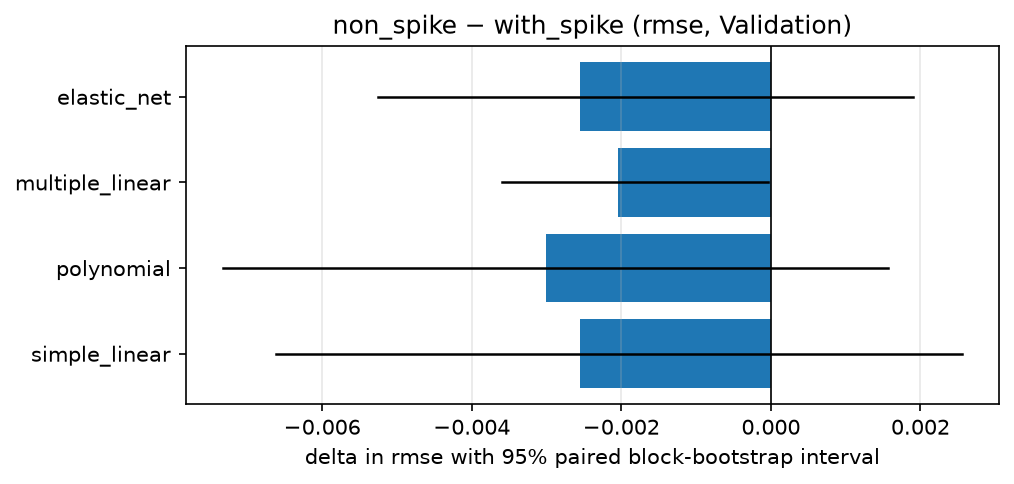

In [13]:
comparison = table(REPORT_ROOT / "comparison_a_vs_b.csv").query("task == 'regression'")
display(comparison[["model", "rmse_with_spike", "rmse_non_spike", "rmse_delta", "rmse_delta_low",
                    "rmse_delta_high", "verdict"]].round(5))
show_image(FIGURE_ROOT / "comparison_delta_regression.png", width=760)

## 11. สรุป

**ข้อค้นพบ**

1. โมเดล regression ทั้ง 4 ตัวได้ RMSE บน Validation ต่ำกว่า baseline ทั้งสองตัว แต่ R² อยู่ใกล้ศูนย์หรือติดลบ จึงเป็นการชนะแบบบาง ๆ
2. แยกอันดับระหว่าง 4 โมเดลไม่ได้ทางสถิติ `elastic_net` มี RMSE ต่ำสุดและถูกใช้เป็นตัวแทน แต่ไม่ได้แปลว่าดีกว่าตัวอื่นอย่างมีนัยสำคัญ
3. การตัด spike ออกทำให้ RMSE ลดลงเล็กน้อยทุกโมเดล แต่ช่วงความเชื่อมั่นส่วนใหญ่คร่อมศูนย์ จึงยังสรุปไม่ได้ว่าช่วยจริง

**ข้อจำกัด**

1. Validation ครอบคลุมสภาพตลาดแบบเดียว (ค่อนข้างสงบ) ผลอาจไม่เหมือนเดิมเมื่อตลาดผันผวนแรง
2. ตัวเลขทั้งหมดเป็น selection score ผลบน Test ซึ่งอ่านครั้งเดียวอยู่ใน `05_results_comparison.ipynb`

cell สุดท้ายบันทึกว่า notebook นี้อ่าน artifact ชุดไหน เพื่อให้ตรวจย้อนได้ว่าตรงกับรายงาน

In [14]:
import matplotlib

provenance = []
for variant in VARIANTS:
    for run in read_runs(OUTPUT_ROOT, variant, task=TASK):
        provenance.append({"variant": variant, "model": run.name,
                           "train_sha256": run.config["train_sha256"][:16],
                           "validation_sha256": run.config["validation_sha256"][:16]})
display(pd.DataFrame(provenance))
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__,
      "| matplotlib", matplotlib.__version__)

,variant,model,train_sha256,validation_sha256
0,with_spike,elastic_net,424f1bda5c4211ac,b84a5fa31fe1afc6
1,with_spike,multiple_linear,424f1bda5c4211ac,b84a5fa31fe1afc6
2,with_spike,polynomial,424f1bda5c4211ac,b84a5fa31fe1afc6
3,with_spike,simple_linear,424f1bda5c4211ac,b84a5fa31fe1afc6
4,non_spike,elastic_net,34fc39d92eeec76b,b84a5fa31fe1afc6
5,non_spike,multiple_linear,34fc39d92eeec76b,b84a5fa31fe1afc6
6,non_spike,polynomial,34fc39d92eeec76b,b84a5fa31fe1afc6
7,non_spike,simple_linear,34fc39d92eeec76b,b84a5fa31fe1afc6


Python 3.14.8 | NumPy 2.5.3 | pandas 3.0.6 | matplotlib 3.11.2
